In [1]:
import torch
import kagglehub
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder

from model.GAN import GAN
import matplotlib.pyplot as plt

/home/vansh/.venvs/core/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [25]:
DEVICE = "cpu"

gan = GAN(latent_dim=128, device=DEVICE, dtype=torch.float32)

checkpoint = torch.load("checkpoints/gan_epoch_34.pt", map_location=DEVICE)
print(checkpoint.keys())
gan.generator.load_state_dict(checkpoint["generator_state_dict"])


dict_keys(['generator_state_dict', 'discriminator_state_dict', 'optimizer_G_state_dict', 'optimizer_D_state_dict', 'epoch'])


<All keys matched successfully>

### Generated Images:

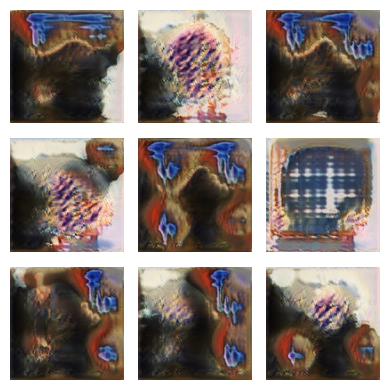

In [30]:
rows, cols = 3, 3

generated_images = gan.sample(num_samples=rows * cols)

fig, axes = plt.subplots(rows, cols, figsize=(4, 4))
for i, image in enumerate(generated_images):
    image = image.detach().cpu().numpy().transpose(1, 2, 0)
    axes[i//cols, i%cols].imshow(image)
    axes[i//cols, i%cols].axis("off")


plt.tight_layout()

### Real Images:

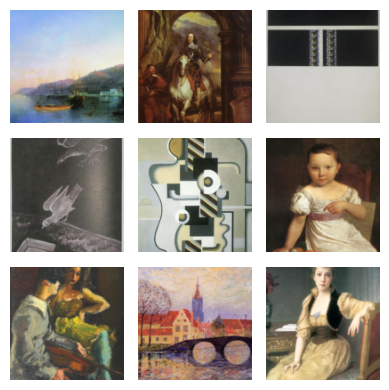

In [20]:
dataset_path = kagglehub.dataset_download("steubk/wikiart")
IMAGE_SIZE = 128

transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),                # shorter side -> 128 (keeps aspect ratio)
    transforms.CenterCrop(IMAGE_SIZE),            # square 128x128 crop, no stretching
    transforms.RandomHorizontalFlip(),            # free augmentation, paintings still look like paintings
    transforms.ToTensor(),                        # [0, 1]
])

dataset = ImageFolder(root=dataset_path, transform=transform)

indexes = torch.randperm(len(dataset))[:rows * cols]

fig, axes = plt.subplots(rows, cols, figsize=(4, 4))
for i in range(rows * cols):
    image, _ = dataset[indexes[i]]
    image = image.detach().cpu().numpy().transpose(1, 2, 0)
    axes[i//cols, i%cols].imshow(image)
    axes[i//cols, i%cols].axis("off")

plt.tight_layout()
